# **Maestría en Inteligencia Artificial Aplicada**

## **Curso: Operaciones de aprendizaje automático**

**Tecnológico de Monterrey**

Prof Ivan Reyes Amezcua
Prof Ricardo Valdez Hernández

Actividad de Semana 3

### **Dataset - Notebook | Individual**

* **Nombre:** Josué Ulises Orozco González

* **matrícula:** A01840988

------------

# **Paso 1: Carga y describe el dataset:**

* #### **Importa los datos en un notebook.**
* #### **Describe su estructura (número de registros, variables, tipos y significado).**

In [4]:
# First, we need to add the libraries needed for the project

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

#Adding library to get norm curve for the data
from scipy.stats import norm
#Adding library to display dataframe data
from IPython.display import display

from pathlib import Path
import sys

project_root = Path.cwd().parent  # from Proyecto\notebooks, this is Proyecto
sys.path.insert(0, str(project_root))

from operaciones_aprendizaje_automatico.config import RAW_DATA_DIR, FILENAME_RAW_DATA

In [5]:
#Loading the data from the CSV file, taking file name and path from the config.py file
def load_data_from_csv():
    file_path = RAW_DATA_DIR / FILENAME_RAW_DATA
    dataframe = pd.read_csv(file_path)

    return dataframe

df = load_data_from_csv()

# Use method shape to get rows and column numbers
print(f"Tamaño del DataFrame:", df.shape)
print(f"\n")

# Use method info from pandas to get summary types
print(f"Utilizando método info() para obtener un resumen de los tipos:")
display(df.info())

# Print first 5 rows to verify data
print(f"Utilizando método head() para obtener los primeros 5 registros del dataframe:")
display(df.head(5))

# Get numerical and categorical columns number which will be useful for graphics
num_cols = df.select_dtypes(include='number').columns.tolist()
cat_cols  = df.select_dtypes(include=['str', 'category']).columns.tolist()

print(f"Columnas númericas: ", num_cols)
print(f"Columnas categoricas: ", cat_cols)

Tamaño del DataFrame: (1470, 35)


Utilizando método info() para obtener un resumen de los tipos:
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInv

None

Utilizando método head() para obtener los primeros 5 registros del dataframe:


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


Columnas númericas:  ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
Columnas categoricas:  ['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime']


## Descripción de las variables

| Variable | Tipo | Significado |
|---|---|---|
| Age | Numérica discreta | Edad del empleado |
| Attrition | Categórica binaria | Indica si el empleado dejó la empresa |
| BusinessTravel | Categórica nominal | Frecuencia de viajes de trabajo |
| DailyRate | Numérica discreta | Tarifa diaria registrada |
| Department | Categórica nominal | Departamento del empleado |
| DistanceFromHome | Numérica discreta | Distancia de casa al trabajo |
| Education | Categórica ordinal | Nivel educativo (1-5) |
| EducationField | Categórica nominal | Campo de estudios |
| EmployeeCount | Numérica discreta | Número de empleados representados |
| EmployeeNumber | Identificador | Identificador único del empleado |
| EnvironmentSatisfaction | Categórica ordinal | Satisfacción con el ambiente (1-4) |
| Gender | Categórica nominal | Género |
| JobInvolvement | Categórica ordinal | Nivel de involucramiento laboral (1-4) |
| JobLevel | Categórica ordinal | Nivel del puesto (1-5) |
| JobRole | Categórica nominal | Puesto del empleado |
| JobSatisfaction | Categórica ordinal | Satisfacción laboral (1-4) |
| MaritalStatus | Categórica nominal | Estado civil |
| MonthlyIncome | Numérica discreta | Ingreso mensual |
| NumCompaniesWorked | Numérica discreta | Número de empresas anteriores |
| Over18 | Categórica binaria | Indica si el empleado es mayor de 18 años |
| OverTime | Categórica binaria | Indica si realiza horas extra |
| PercentSalaryHike | Numérica discreta | Porcentaje de incremento salarial |
| PerformanceRating | Categórica ordinal | Evaluación de desempeño (1-4) |
| RelationshipSatisfaction | Categórica ordinal | Satisfacción con las relaciones (1-4) |
| StandardHours | Numérica discreta | Horas estándar |
| StockOptionLevel | Numérica ordinal | Nivel de opciones sobre acciones |
| TotalWorkingYears | Numérica discreta | Años totales de experiencia laboral |
| TrainingTimesLastYear | Numérica discreta | Capacitaciones durante el último año |
| WorkLifeBalance | Categórica ordinal | Equilibrio vida-trabajo (1-4) |
| YearsAtCompany | Numérica discreta | Años en la empresa |
| YearsInCurrentRole | Numérica discreta | Años en el puesto actual |
| YearsSinceLastPromotion | Numérica discreta | Años desde el último ascenso |
| YearsWithCurrManager | Numérica discreta | Años con el gerente actual |

# **Paso 2: Realiza un análisis exploratorio (EDA):**

* #### **Genera estadísticas descriptivas y visualizaciones que te permitan entender la distribución de las variables y las relaciones entre ellas.**

**************************************************
** Datos numericos -- Estadisticas descriptivas **
**************************************************
** Estadisticas descriptivas del dataframe para sus valores numéricos **



,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0,0.413286,-0.404145
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0,-0.003519,-1.203823
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0,0.958118,-0.224833
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0,-0.289681,-0.559115
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0,0.000000,0.000000
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0,0.016574,-1.223179
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0,-0.321654,-1.202521
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0,-0.032311,-1.196398
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0,-0.498419,0.270999
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0,1.025401,0.399152


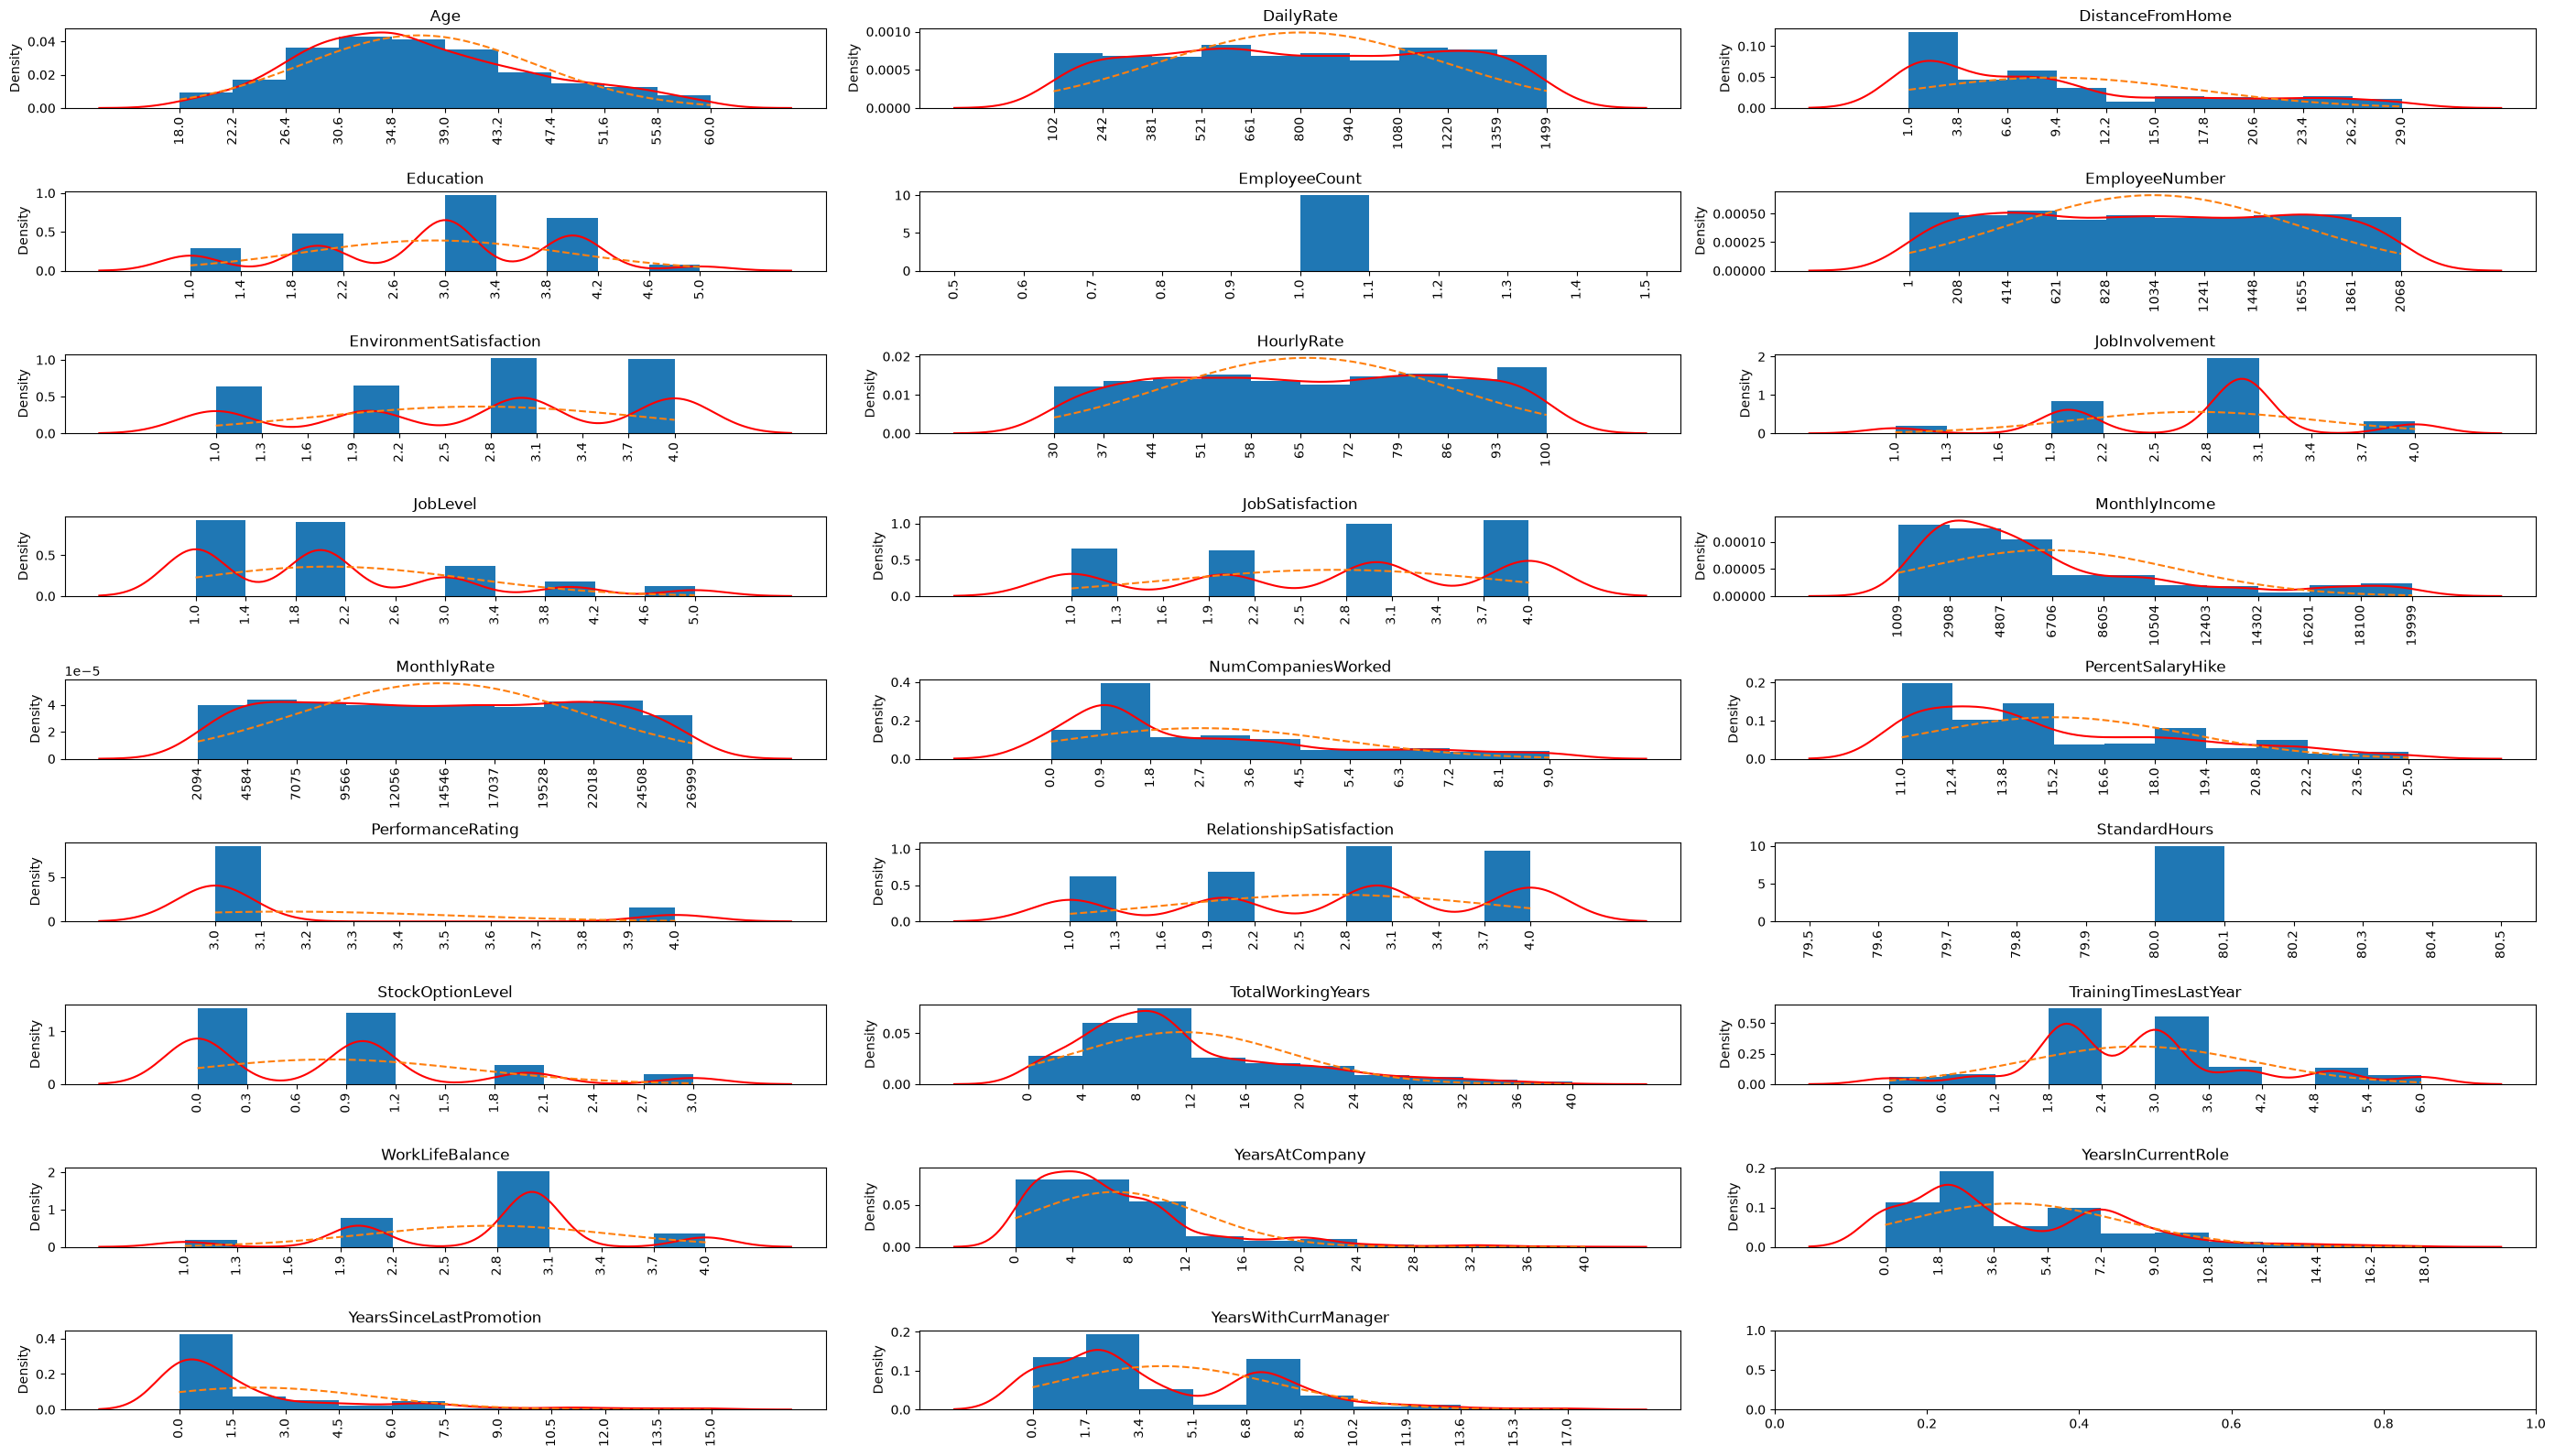


Generamos un boxplot de las variables numericas para revisar outliers...


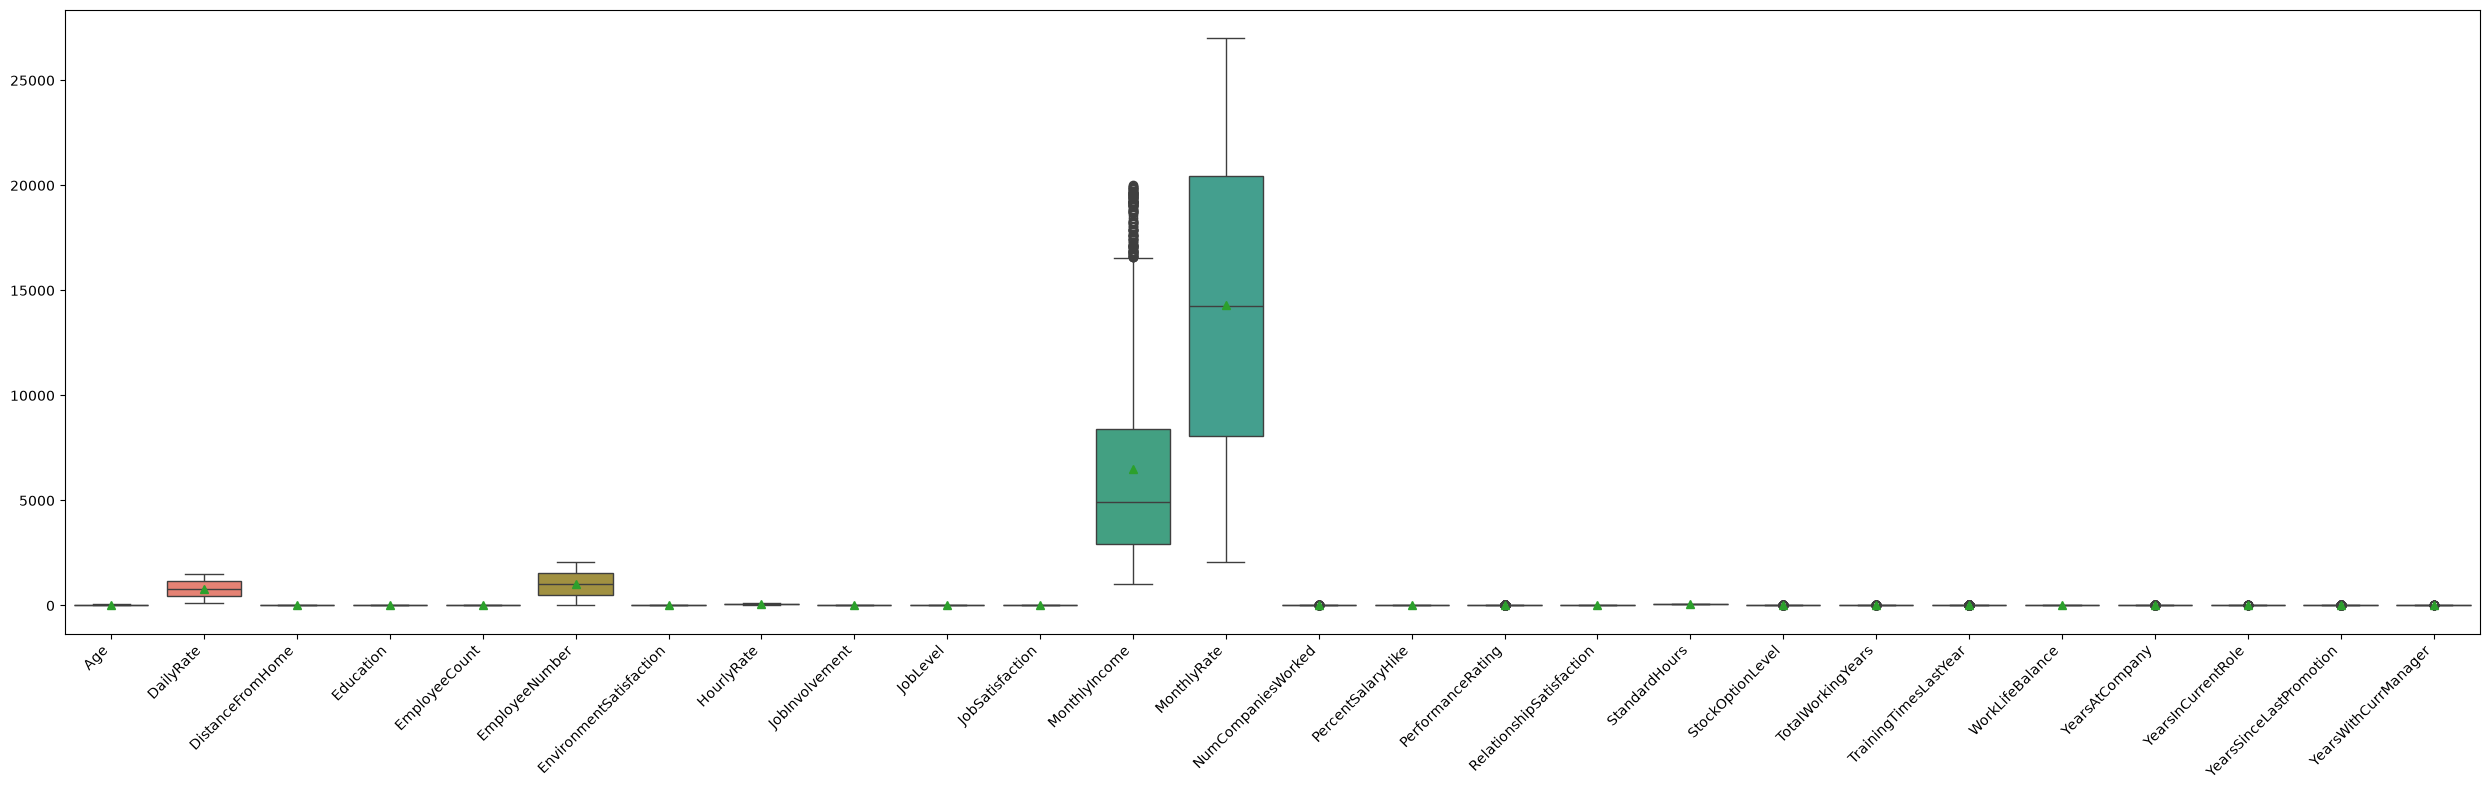

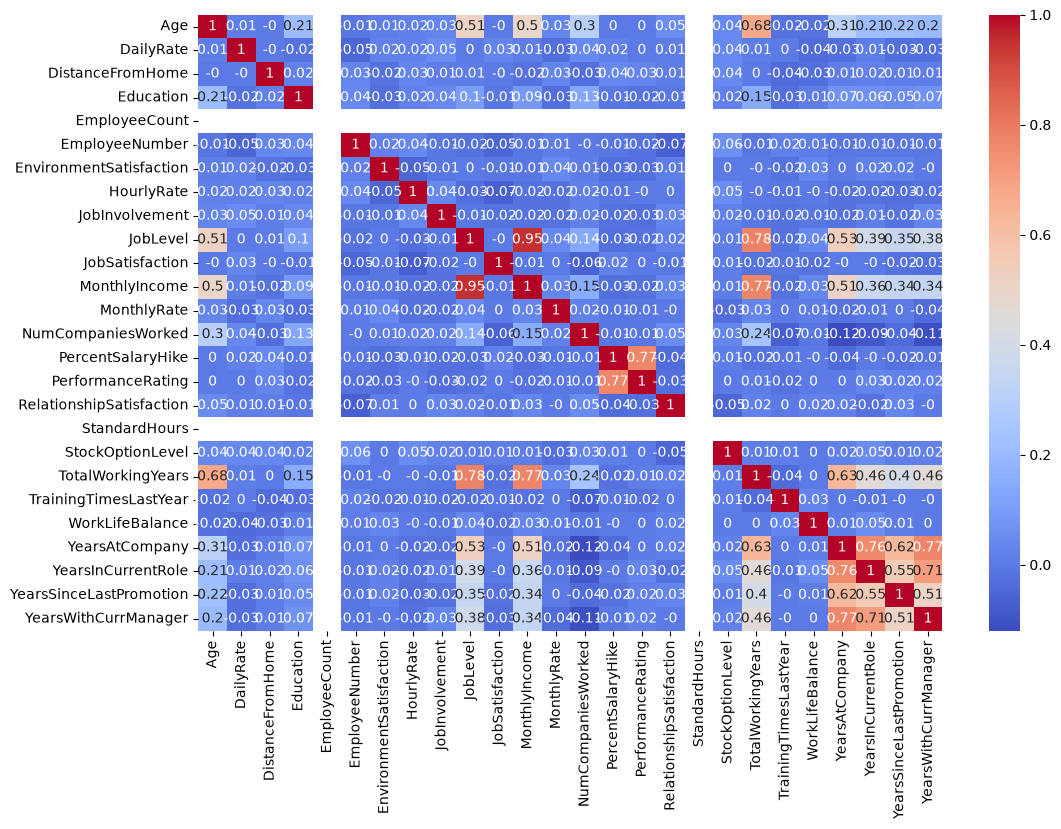

In [6]:
# Get descriptive statistics from the dataframe

# ** Numerical values **
print(f'**************************************************')
print(f'** Datos numericos -- Estadisticas descriptivas **')
print(f'**************************************************')

# Get descriptive statistics from the dataframe adding skewness and kurtosis
desc = df[num_cols].describe()

# Get Skewness (Asymmetry) and Kurtosis
skewness = df.skew(numeric_only=True).to_frame(name='skew').T
kurtosis = df.kurt(numeric_only=True).to_frame(name='kurtosis').T

# Combine in single datagrame using concat method
desc = pd.concat([desc, skewness, kurtosis])

print(f'** Estadisticas descriptivas del dataframe para sus valores numéricos **\n')
display(desc.T)

print(f'\n')

# ** Generating histograms using matplotlib and seaborn **
fig, axes = plt.subplots(9,3, figsize=(28,16))
plt.subplots_adjust(wspace=0.5)

axes = axes.ravel()

for col, ax in zip(num_cols, axes):
  values = df[col].dropna() # Check if this is just 1 value to graphic curve
  
  # Histograma
  n, bins, patches = ax.hist(values, density=True)
  
  if values.nunique() > 1:
    # KDE
    sns.kdeplot(df[col], ax=ax, color='red', warn_singular=False)

    # Parámetros de distribución normal
    mu = df[col].mean()
    sigma = df[col].std()

    # Valores para curva normal
    x_vals = np.linspace(df[col].min(), df[col].max(), 1000)

    normal_ref = norm.pdf(x_vals, loc=mu, scale=sigma)
    # Graficar curva normal
    ax.plot(x_vals, normal_ref, linestyle='--', label='Normal')

  ax.set_xticks(bins) #Draw bins
  ax.set(title=f'{col}', xlabel=None)
  ax.set_xlabel(None)
  # Rotar etiquetas del eje x
  ax.tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

# Create boxplots for numerical values to check their values and outliers
print("\nGeneramos un boxplot de las variables numericas para revisar outliers...")
plt.figure(figsize=(25,8))
sns.boxplot(data=df[num_cols],
            showmeans=True)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Get correlation matrix
corr_matrix = df[num_cols].corr()

print("\n")
plt.figure(figsize = (12, 8))
sns.heatmap(round(corr_matrix,2), annot=True, cmap='coolwarm')
plt.show()

***************************************************
** Datos categoricos - Estadisticas descriptivas **
***************************************************

** Estadisticas descriptivas del dataframe para sus valores categoricos **



,count,unique,top,freq
Attrition,1470,2,No,1233
BusinessTravel,1470,3,Travel_Rarely,1043
Department,1470,3,Research & Development,961
EducationField,1470,6,Life Sciences,606
Gender,1470,2,Male,882
JobRole,1470,9,Sales Executive,326
MaritalStatus,1470,3,Married,673
Over18,1470,1,Y,1470
OverTime,1470,2,No,1054



Frecuencia de las categorias.


Attrition
No     1233
Yes     237
Name: count, dtype: int64

BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150
Name: count, dtype: int64

...

Gender
Male      882
Female    588
Name: count, dtype: int64

JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Name: count, dtype: int64

MaritalStatus
Married     673
Single      470
Divorced    327
Name: count, dtype: int64

Over18
Y    1470
Name: count, dtype: int64

OverTime
No     1054
Yes     416
Name: count, dtype: int64

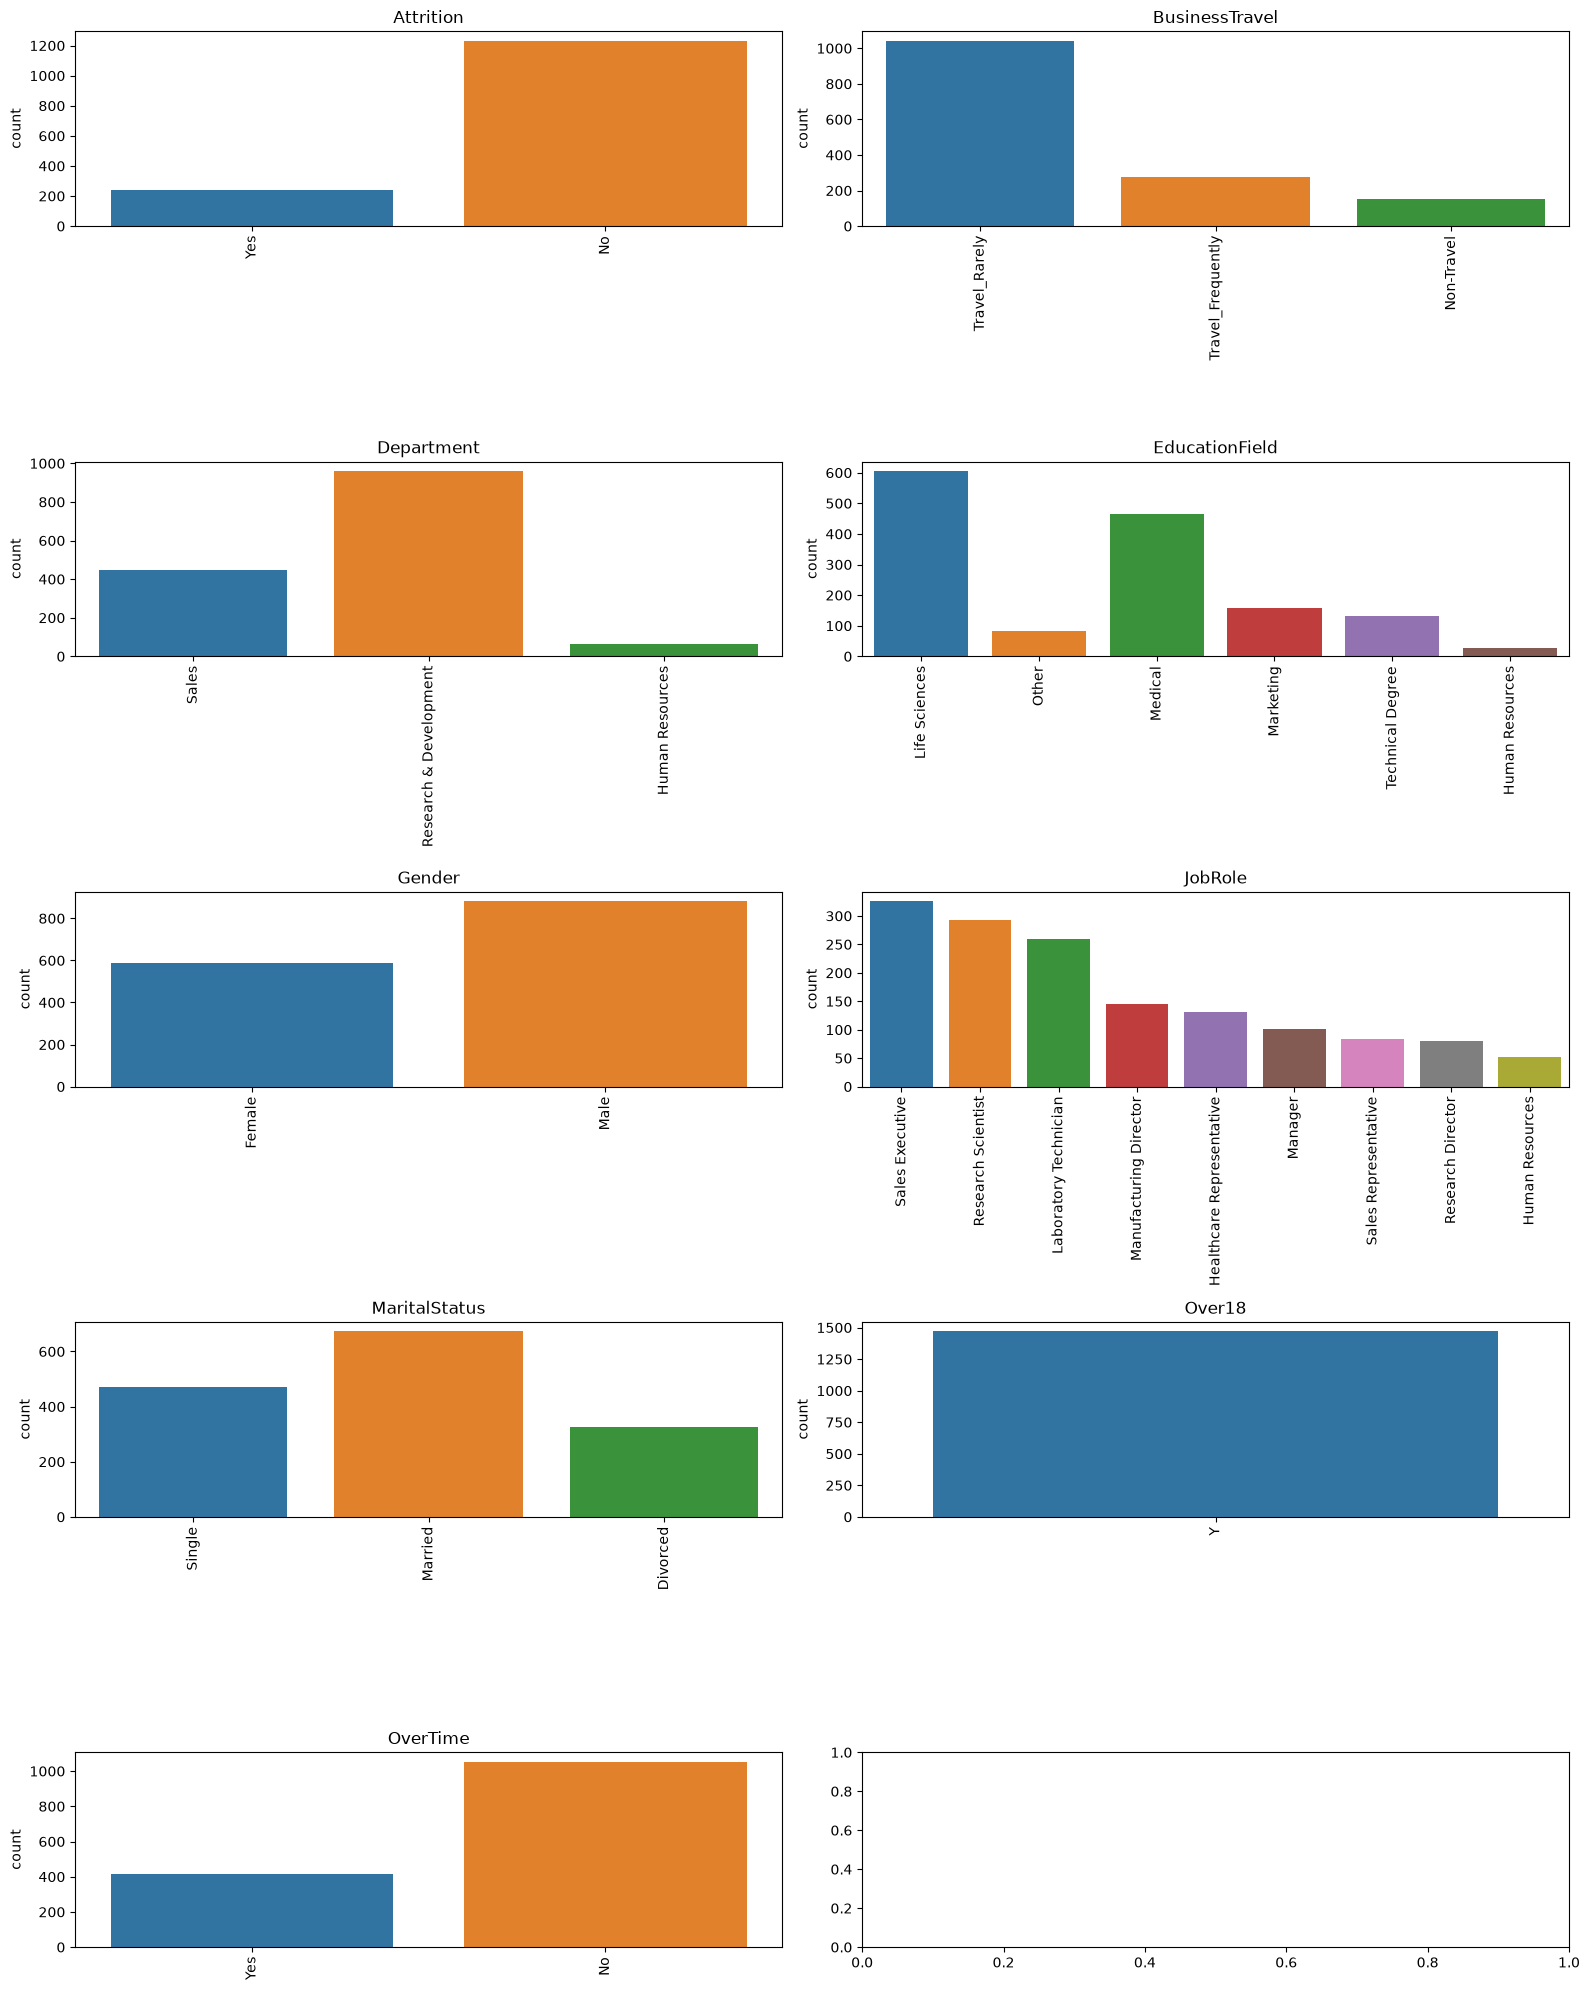

In [7]:
# ** Categorical values **
print(f'***************************************************')
print(f'** Datos categoricos - Estadisticas descriptivas **')
print(f'***************************************************\n')

# ** Categorical values **
print(f'** Estadisticas descriptivas del dataframe para sus valores categoricos **\n')
display(df[cat_cols].describe().T)

print(f'\nFrecuencia de las categorias.')
for col in cat_cols:
  display(df[col].value_counts())

print(f'\n')

fig, axes = plt.subplots(5,2, figsize=(16,20))
plt.subplots_adjust(hspace=2.5)
axes = axes.ravel()
for col, ax in zip(cat_cols, axes):
  # Get cardinality
  cardinality = df[col].nunique()
  #Check if cardinality is highter than 10 to check for frequent values
  if cardinality > 10:
    # Top 10 more frequent values
    top_10 = df[col].value_counts().nlargest(10).index

    # Filter dataframe to verify if data is in top 10
    filtered_df = df[df[col].isin(top_10)]

    #Assign these values to the plot
    xPlot = filtered_df[col]
    huePlot = filtered_df[col]
  else:
    # Not high cardinality, take values normally
    xPlot = df[col]
    huePlot = df[col]
    pass

  sns.countplot(x=xPlot, hue=huePlot, ax=ax) # ---> Seaborn

  ax.set(title=f'{col}', xlabel=None)
  ax.tick_params(axis='x',rotation=90)

plt.tight_layout()
plt.show()

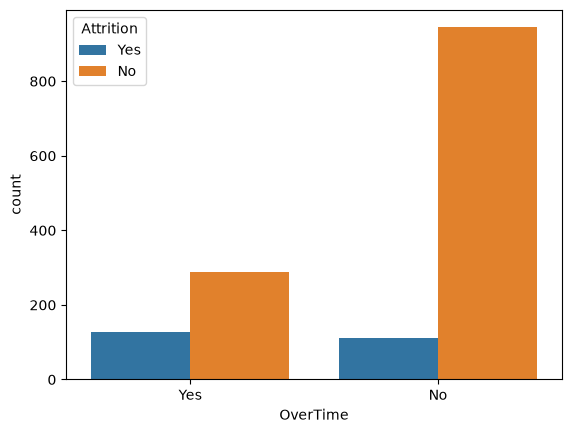

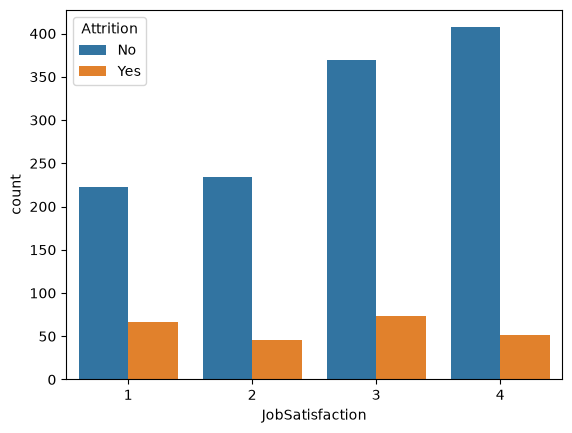

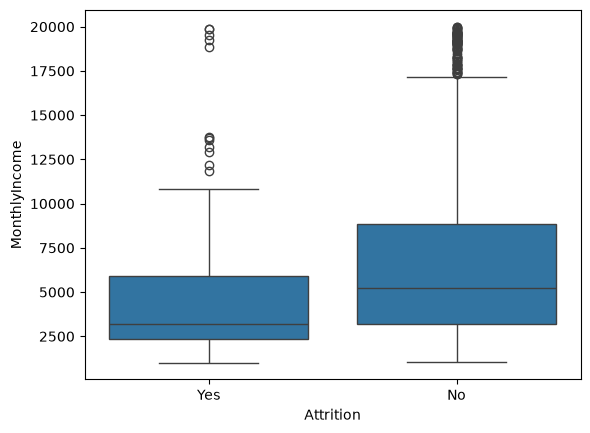

In [8]:
#Analisis respectro a la variable objetivo
sns.countplot(data=df, x='OverTime', hue='Attrition')
plt.show()

sns.countplot(data=df, x='JobSatisfaction', hue='Attrition')
plt.show()

sns.boxplot(data=df, x='Attrition', y='MonthlyIncome')
plt.show()

Josue O - Observaciones del análisis exploratorio

A partir de las estadísticas descriptivas, histogramas y boxplots se
observa que algunas variables numéricas presentan distribuciones
asimétricas y posibles valores atípicos.

La matriz de correlación permite identificar relaciones entre las
variables numéricas y detectar variables que presentan una fuerte correlacion
entre ellas.

Los histogramas y las curvas KDE permiten observar que no todas las
variables presentan una distribución aproximadamente normal, por lo que
sirve para evaluar las transformaciones necesarias a aplicar en el modelo

En cuanto a las variables categóricas, las tablas de frecuencia y los gráficos
de barras permiten identificar la distribución de las diferentes categorías.
También se identifican variables con pocas categorías y otras con mayor cardinalidad.

Las variables categóricas ordinales presentan niveles que representan diferentes
grados de una característica. Por ello, durante la preparación de los datos deberá
conservarse este mismo orden. En contraste, las variables categóricas 
nominales representan grupos sin un orden establecido y deberán tratarse de manera
diferente durante la transformación de los datos.

La exploración de las variables numéricas y categóricas proporciona información del dataset
y como esta compuesto, y de que tipo de variables.
Estos resultados servirán como referencia para las siguientes etapas de limpieza, transformación,
selección de variables y construcción del modelo predictivo.